# Étape 4 — Règles d'association

**Objectif :** découvrir quels **gaz anormaux apparaissent ensemble** dans un même prélèvement, et quelles combinaisons de gaz
conduisent l'expert à **recommander une action**.

**Méthode :** algorithme **Apriori** (bibliothèque `mlxtend`).

**Plan :**
1. Charger les données
2. Préparer les transactions (format requis par Apriori)
3. Extraire les itemsets fréquents (Apriori)
4. Générer les règles d'association
5. Interpréter les règles

## 1. Charger les données

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from mlxtend.frequent_patterns import apriori, association_rules

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
pd.set_option("display.max_colwidth", 80)
dossier = Path.cwd() / "data"

# Table prétraitée de l'étape 2 + tables brutes (avis de l'expert et normes IEEE)
table = pd.read_csv(dossier / "processed" / "dga_transformateurs_pretraite.csv")
detail = pd.read_csv(dossier / "raw" / "AnalyseDetail.csv")
recommandations = pd.read_csv(dossier / "raw" / "Recommandation.csv")
normes = pd.read_csv(dossier / "raw" / "NormesC57104.csv")

# Décision de l'expert, construite comme à l'étape 3 : 1 = action, 0 = aucune action, inconnu = pas de texte
reco_gd = recommandations[recommandations["TypeAnalyse"] == "GD"][["CodeRecommandation", "Recommandation"]]
table = table.merge(detail[["CléAnalyse", "CodeRecommandation"]], on="CléAnalyse", how="left")
table = table.merge(reco_gd, on="CodeRecommandation", how="left")
table = table.dropna(subset=["Recommandation"])          # on garde les prélèvements dont la décision est connue
table["action"] = table["Recommandation"] != "Aucune action"

print("Prélèvements utilisés :", len(table))

Prélèvements utilisés : 3870


## 2. Préparer les transactions
Apriori ne travaille pas sur des nombres mais sur des **transactions** : chaque prélèvement est un « panier » qui contient ou non certains **items**.
Il faut donc transformer chaque concentration en un item **vrai / faux**.

**Règle :** un gaz est « élevé » s'il dépasse le **seuil normal de la norme IEEE C57.104** (condition 1, table `NormesC57104` de la base).
Exception : pour l'acétylène, on crée l'item « C2H2 présent » (≥ 2 ppm), car toute trace d'acétylène est déjà un signal d'alerte
(le seuil IEEE de 35 ppm ne concerne que 2 % des prélèvements).

On ne crée que des items **anormaux** : des items « normal » produiraient surtout des règles sans intérêt (« H2 normal → CH4 normal »).

In [2]:
seuils = normes[normes["Condition"] == 1].iloc[0]   # ligne des seuils "normaux" (condition 1)

transactions = pd.DataFrame()
for gaz in ["H2", "CH4", "C2H4", "C2H6", "CO", "CO2"]:
    transactions[gaz + " élevé"] = table[gaz] > seuils[gaz]
    print(f"{gaz:5s} élevé : > {seuils[gaz]:,.0f} ppm")
transactions["C2H2 présent"] = table["C2H2"] >= 2
transactions["Action recommandée"] = table["action"]

transactions.head()

H2    élevé : > 100 ppm
CH4   élevé : > 120 ppm
C2H4  élevé : > 50 ppm
C2H6  élevé : > 65 ppm
CO    élevé : > 350 ppm
CO2   élevé : > 2,500 ppm


,H2 élevé,CH4 élevé,C2H4 élevé,C2H6 élevé,CO élevé,CO2 élevé,C2H2 présent,Action recommandée
0,True,False,False,False,True,True,False,False
1,False,False,False,False,True,True,False,False
2,False,False,False,False,True,True,False,False
3,False,False,False,False,True,True,False,False
4,False,False,False,False,True,True,False,False


In [3]:
# Support de chaque item = part des prélèvements qui le contiennent
(transactions.mean() * 100).sort_values(ascending=False).round(1).to_frame("support (%)")

,support (%)
CO2 élevé,59.000
CO élevé,57.100
C2H4 élevé,21.300
C2H2 présent,17.200
H2 élevé,7.800
Action recommandée,6.700
C2H6 élevé,4.900
CH4 élevé,3.900


**Interprétation :** 
- **CO et CO2 élevés** sont très fréquents (près de 60 % des prélèvements) : c'est le vieillissement normal du papier isolant dans un parc ancien.
- **C2H4 élevé** (21 %) et **C2H2 présent** (17 %) sont assez courants.
- **H2, C2H6 et CH4 élevés** sont rares (4 à 8 %), comme l'**action recommandée** (6,7 %).

## 3. Itemsets fréquents (Apriori)
Un **itemset** est un ensemble d'items présents ensemble dans un prélèvement. Il est **fréquent** si son **support** (la part des prélèvements qui le contiennent)
dépasse un minimum. On fixe ce minimum à **2 %** : assez bas pour garder les items rares mais importants (H2 élevé, action).

In [4]:
itemsets = apriori(transactions, min_support=0.02, use_colnames=True)   # use_colnames : afficher les noms des items
itemsets["nb_items"] = itemsets["itemsets"].apply(len)

print("Nombre d'itemsets fréquents :", len(itemsets))
print(itemsets["nb_items"].value_counts().sort_index().rename("nombre d'itemsets"))
itemsets.sort_values("support", ascending=False).head(10)

Nombre d'itemsets fréquents : 85
nb_items
1     8
2    27
3    34
4    14
5     2
Name: nombre d'itemsets, dtype: int64


,support,itemsets,nb_items
5,0.590,(CO2 élevé),1
4,0.571,(CO élevé),1
29,0.466,"(CO2 élevé, CO élevé)",2
2,0.213,(C2H4 élevé),1
22,0.193,"(C2H4 élevé, CO2 élevé)",2
21,0.193,"(C2H4 élevé, CO élevé)",2
57,0.184,"(C2H4 élevé, CO2 élevé, CO élevé)",3
6,0.172,(C2H2 présent),1
30,0.093,"(C2H2 présent, CO élevé)",2
32,0.087,"(CO2 élevé, C2H2 présent)",2


## 4. Générer les règles d'association
Une règle **A → B** se lit « si un prélèvement contient A, alors il contient souvent B ». Trois mesures :

| Mesure | Définition | Lecture |
|---|---|---|
| **Support** | part des prélèvements contenant A **et** B | la règle est-elle fréquente ? |
| **Confiance** | parmi les prélèvements contenant A, part contenant aussi B | la règle est-elle fiable ? |
| **Lift** | confiance / support de B | > 1 : A et B vont ensemble plus souvent que par hasard |

On garde les règles avec un **lift > 1,5** (lien nettement plus fort que le hasard) et une **confiance ≥ 30 %**.

In [5]:
regles = association_rules(itemsets, metric="lift", min_threshold=1.5)
regles = regles[regles["confidence"] >= 0.3]

# Affichage lisible : les ensembles d'items deviennent du texte
regles["si (A)"] = regles["antecedents"].apply(lambda x: " + ".join(sorted(x)))
regles["alors (B)"] = regles["consequents"].apply(lambda x: " + ".join(sorted(x)))
regles = regles[["si (A)", "alors (B)", "support", "confidence", "lift"]]

print("Nombre de règles retenues :", len(regles), "(beaucoup sont des variantes longues : on va filtrer)")

Nombre de règles retenues : 311 (beaucoup sont des variantes longues : on va filtrer)


## 5. Interpréter les règles
### 5.1 Quels gaz anormaux apparaissent ensemble ?

In [6]:
# Pour rester lisible : règles simples "un gaz -> un gaz" (sans le symbole "+"), sans l'item Action
simples = ~regles["si (A)"].str.contains(r"\+") & ~regles["alors (B)"].str.contains(r"\+")
sans_action = ~regles["si (A)"].str.contains("Action") & ~regles["alors (B)"].str.contains("Action")
regles_gaz = regles[simples & sans_action].sort_values("lift", ascending=False)
regles_gaz

,si (A),alors (B),support,confidence,lift
12,CH4 élevé,C2H6 élevé,0.036,0.940,19.342
13,C2H6 élevé,CH4 élevé,0.036,0.745,19.342
1,H2 élevé,CH4 élevé,0.026,0.334,8.686
0,CH4 élevé,H2 élevé,0.026,0.678,8.686
5,C2H6 élevé,H2 élevé,0.026,0.543,6.953
4,H2 élevé,C2H6 élevé,0.026,0.338,6.953
10,CH4 élevé,C2H4 élevé,0.033,0.859,4.040
19,C2H6 élevé,C2H4 élevé,0.036,0.745,3.502
26,C2H6 élevé,C2H2 présent,0.021,0.431,2.507
3,H2 élevé,C2H4 élevé,0.033,0.424,1.993


**Interprétation :** 
- **CH4 élevé ↔ C2H6 élevé** (lift 19) : quand le méthane est élevé, l'éthane l'est aussi dans **94 %** des cas. Ces deux gaz forment la signature d'une **surchauffe de l'huile** à température modérée.
- **H2 élevé** accompagne ces deux gaz (lift 7 à 9) : l'hydrogène apparaît avec les défauts thermiques et les décharges partielles.
- **CH4 / C2H6 élevés → C2H4 élevé** (confiance 75 à 86 %) : quand la surchauffe s'intensifie, l'éthylène apparaît.
- **C2H4 élevé → CO élevé** (91 %) : une surchauffe touche souvent aussi le papier isolant.
- Le lien avec l'acétylène est plus faible (lift 1,8 à 2,5) : l'arc électrique est un défaut à part.

→ Sans aucune connaissance préalable, Apriori retrouve les **familles de gaz** connues des experts : les hydrocarbures (CH4, C2H6, C2H4, H2) sont produits **ensemble** par un même défaut.

### 5.2 Quelles combinaisons conduisent l'expert à recommander une action ?
Sans information, la probabilité d'une action est d'environ **7 %** (support de l'item). Une règle utile doit faire nettement mieux.

In [7]:
regles_action = regles[regles["alors (B)"] == "Action recommandée"].sort_values("confidence", ascending=False)
regles_action

,si (A),alors (B),support,confidence,lift
103,C2H4 élevé + CH4 élevé,Action recommandée,0.021,0.625,9.303
131,CH4 élevé + CO élevé,Action recommandée,0.021,0.600,8.931
16,CH4 élevé,Action recommandée,0.023,0.591,8.791
118,C2H6 élevé + CH4 élevé,Action recommandée,0.021,0.579,8.612
144,C2H4 élevé + C2H6 élevé,Action recommandée,0.020,0.557,8.293
176,C2H6 élevé + CO élevé,Action recommandée,0.021,0.547,8.146
180,C2H6 élevé + CO2 élevé,Action recommandée,0.020,0.513,7.636
28,C2H6 élevé,Action recommandée,0.025,0.505,7.521
367,C2H2 présent + CO élevé + CO2 élevé,Action recommandée,0.023,0.345,5.133
8,H2 élevé,Action recommandée,0.024,0.308,4.584


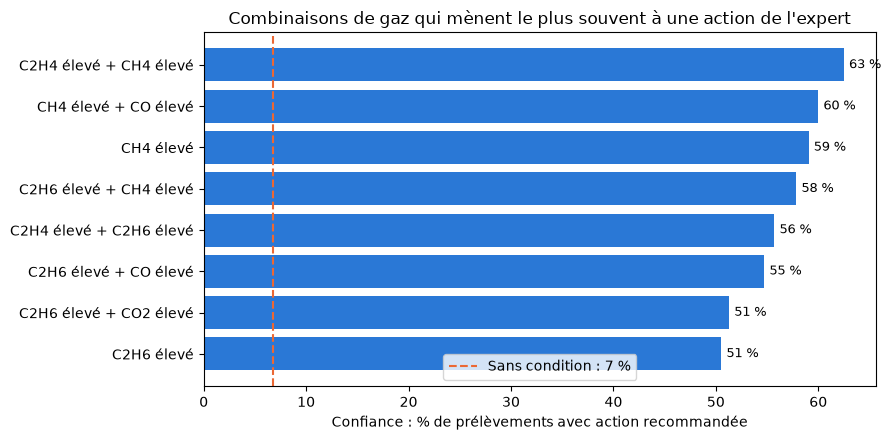

In [8]:
# Graphique : confiance des règles menant à une action, comparée à la probabilité de base
base = transactions["Action recommandée"].mean() * 100
top = regles_action.head(8).iloc[::-1]          # 8 meilleures règles, la meilleure en haut

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(top["si (A)"], top["confidence"] * 100, color="#2a78d6")
ax.axvline(base, color="#eb6834", linestyle="--", label=f"Sans condition : {base:.0f} %")
for y, v in enumerate(top["confidence"] * 100):
    ax.text(v + 0.5, y, f"{v:.0f} %", va="center", fontsize=9)
ax.set_xlabel("Confiance : % de prélèvements avec action recommandée")
ax.set_title("Combinaisons de gaz qui mènent le plus souvent à une action de l'expert")
ax.legend()
plt.tight_layout()
plt.show()

**Interprétation :** 
- Sans condition, l'expert recommande une action dans **6,7 %** des cas.
- **CH4 élevé + C2H4 élevé → action : 62 %** des cas (lift 9,3). C'est la règle la plus fiable.
- **CH4 élevé seul → action : 59 %** ; **C2H6 élevé → action : 50 %** ; **H2 élevé → action : 31 %**.
- La seule **présence d'acétylène** ne suffit pas : elle n'apparaît dans une règle vers l'action qu'associée à CO et CO2 (35 %).

→ Les situations qui déclenchent le plus souvent une action sont les **surchauffes de l'huile** (CH4, C2H6, C2H4). C'est cohérent avec l'étape 3, où H2, CH4 et C2H6 étaient les gaz les plus importants pour la forêt aléatoire.

→ Même la meilleure règle n'atteint que 62 % de confiance : 4 fois sur 10, l'expert n'a pas recommandé d'action. Il tient compte d'autres éléments, comme l'évolution des gaz dans le temps.

## Bilan de l'étape 4
| Élément | Résultat |
|---|---|
| Transactions | 3 870 prélèvements, 8 items (7 gaz anormaux selon IEEE C57.104 + action de l'expert) |
| Itemsets fréquents (support ≥ 2 %) | 85 |
| Règles retenues (lift > 1,5, confiance ≥ 30 %) | 311, filtrées pour l'interprétation |
| Gaz associés | CH4 ↔ C2H6 (lift 19), avec H2 et C2H4 : signature de la surchauffe de l'huile |
| Règle la plus fiable vers l'action | CH4 élevé + C2H4 élevé → action dans 62 % des cas (contre 6,7 % en moyenne) |

**Limite :** les supports sont faibles (2 à 4 %) : ces situations sont rares, mais ce sont précisément celles qui comptent pour la maintenance.

**Prochaine étape :** visualisation et interprétation.